In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
df = pd.read_csv("loan_approval_dataset.csv")

In [3]:
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,NotGraduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,NotGraduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   loan_id                   4269 non-null   int64
 1   no_of_dependents          4269 non-null   int64
 2   education                 4269 non-null   str  
 3   self_employed             4269 non-null   str  
 4   income_annum              4269 non-null   int64
 5   loan_amount               4269 non-null   int64
 6   loan_term                 4269 non-null   int64
 7   cibil_score               4269 non-null   int64
 8   residential_assets_value  4269 non-null   int64
 9   commercial_assets_value   4269 non-null   int64
 10  luxury_assets_value       4269 non-null   int64
 11  bank_asset_value          4269 non-null   int64
 12  loan_status               4269 non-null   str  
dtypes: int64(10), str(3)
memory usage: 433.7 KB


In [5]:
df.shape

(4269, 13)

In [6]:
df.isnull().sum()

loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64

In [7]:
# Select Independent and Dependent Variables
X = df[['income_annum', 'cibil_score', 'loan_term']]
y = df['loan_amount']
print("Independent Variables:")
print(X.head())
print("\nDependent Variable:")
print(y.head())

Independent Variables:
   income_annum  cibil_score  loan_term
0       9600000          778         12
1       4100000          417          8
2       9100000          506         20
3       8200000          467          8
4       9800000          382         20

Dependent Variable:
0    29900000
1    12200000
2    29700000
3    30700000
4    24200000
Name: loan_amount, dtype: int64


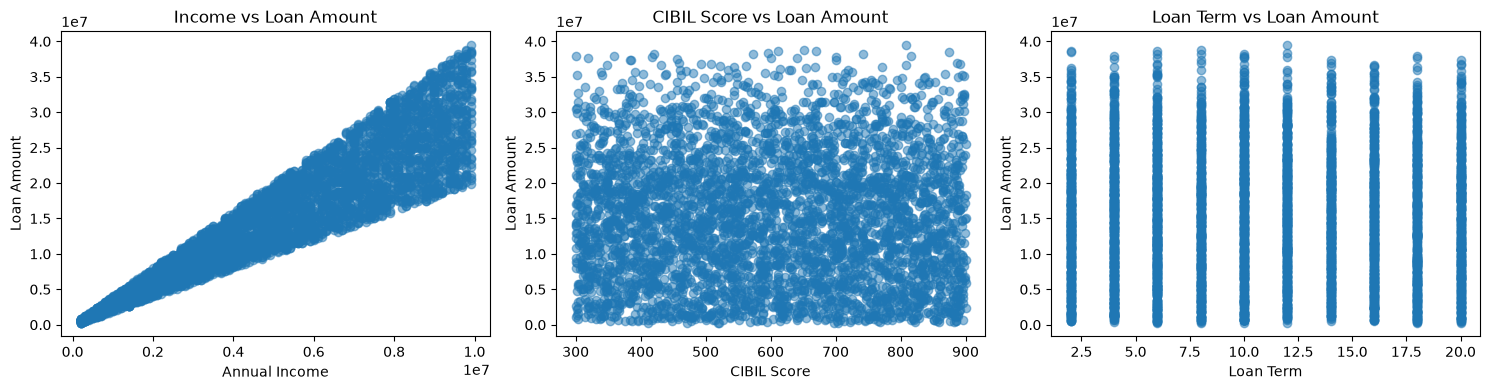

In [8]:
# Individual Relationship Between Independent and Dependent Variables
plt.figure(figsize=(15, 4))

# Graph 1: Annual Income vs Loan Amount
plt.subplot(1, 3, 1)
plt.scatter(df['income_annum'], df['loan_amount'], alpha=0.5)
plt.xlabel('Annual Income')
plt.ylabel('Loan Amount')
plt.title('Income vs Loan Amount')

# Graph 2: CIBIL Score vs Loan Amount
plt.subplot(1, 3, 2)
plt.scatter(df['cibil_score'], df['loan_amount'], alpha=0.5)
plt.xlabel('CIBIL Score')
plt.ylabel('Loan Amount')
plt.title('CIBIL Score vs Loan Amount')

# Graph 3: Loan Term vs Loan Amount
plt.subplot(1, 3, 3)
plt.scatter(df['loan_term'], df['loan_amount'], alpha=0.5)
plt.xlabel('Loan Term')
plt.ylabel('Loan Amount')
plt.title('Loan Term vs Loan Amount')
plt.tight_layout()
plt.show()

In [9]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (3415, 3)
Testing Data: (854, 3)


In [10]:
# Create Multiple Linear Regression Model
model = LinearRegression()
# Train the model
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 2.99, 237.62,-1368.1 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['income_annum','cibil_score','loan_term']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.099e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [11]:
# Display model coefficients and intercept
print("Model Coefficients:")
for feature, coefficient in zip(X.columns, model.coef_):
    print(feature, ":", coefficient)
print("\nModel Intercept:", model.intercept_)

Model Coefficients:
income_annum : 2.994136882358957
cibil_score : 237.61944275415138
loan_term : -1368.1022138630005

Model Intercept: -109935.1507994663


In [12]:
# Predict loan amounts using test data
y_pred = model.predict(X_test)

In [13]:
# Compare Actual and Predicted Loan Amounts
comparison = pd.DataFrame({
    'Actual Loan Amount': y_test.values,
    'Predicted Loan Amount': y_pred
})
comparison['Difference'] = (
    comparison['Actual Loan Amount'] -
    comparison['Predicted Loan Amount']
)
comparison.head(10)

,Actual Loan Amount,Predicted Loan Amount,Difference
0,19700000,1.613155e+07,3.568445e+06
1,14000000,1.768686e+07,-3.686862e+06
2,19900000,2.872203e+07,-8.822029e+06
3,23400000,1.858653e+07,4.813472e+06
4,14100000,1.741500e+07,-3.315005e+06
5,12500000,1.411267e+07,-1.612669e+06
6,13500000,1.022123e+07,3.278765e+06
7,13700000,1.526623e+07,-1.566235e+06
8,8500000,9.893544e+06,-1.393544e+06
9,6000000,8.973673e+06,-2.973673e+06


In [14]:
# Evaluate Model Performance
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("MODEL EVALUATION RESULTS")
print("------------------------")
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R-Squared (R2):", r2)
print("R-Squared Percentage:", round(r2 * 100, 2), "%")

MODEL EVALUATION RESULTS
------------------------
Mean Squared Error (MSE): 11889401699291.46
Root Mean Squared Error (RMSE): 3448101.1730068857
R-Squared (R2): 0.8517250601560622
R-Squared Percentage: 85.17 %


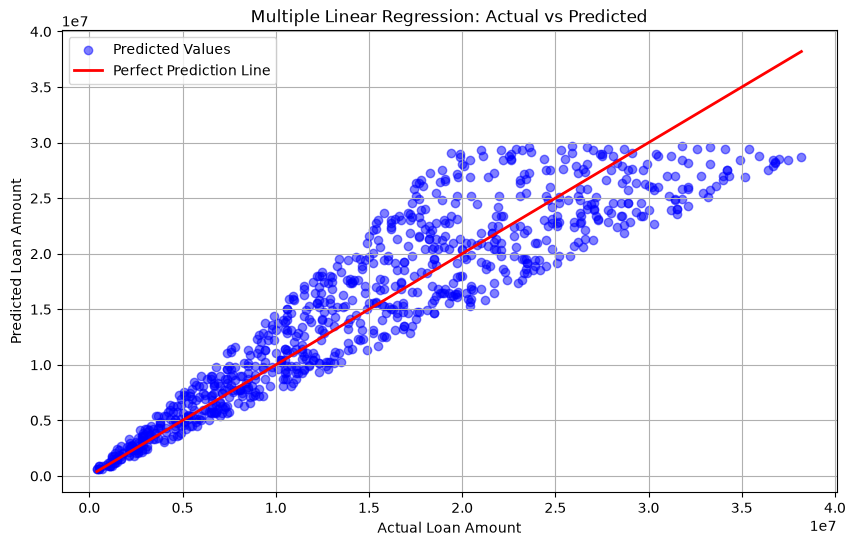

In [15]:
# Actual vs Predicted Loan Amount Graph

plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    y_pred,
    color='blue',
    alpha=0.5,
    label='Predicted Values'
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linewidth=2,
    label='Perfect Prediction Line'
)

plt.xlabel("Actual Loan Amount")
plt.ylabel("Predicted Loan Amount")

plt.title("Multiple Linear Regression: Actual vs Predicted")

plt.legend()
plt.grid(True)

plt.show()

In [16]:
# Final Model Summary

print("MULTIPLE LINEAR REGRESSION - BANK LOAN ANALYSIS")
print("-----------------------------------------------")

print("Independent Variables: Income, CIBIL Score, Loan Term")
print("Dependent Variable: Loan Amount")
print("Algorithm: Multiple Linear Regression")

print("\nModel Performance:")
print("R-Squared:", round(r2, 4))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))

MULTIPLE LINEAR REGRESSION - BANK LOAN ANALYSIS
-----------------------------------------------
Independent Variables: Income, CIBIL Score, Loan Term
Dependent Variable: Loan Amount
Algorithm: Multiple Linear Regression

Model Performance:
R-Squared: 0.8517
MSE: 11889401699291.46
RMSE: 3448101.17


### Conclusion

Multiple Linear Regression was performed to predict loan amounts using three independent variables: annual income, CIBIL score and loan term. The model achieved an R-squared value of 0.8517, indicating that approximately 85.17% of the variation in loan amount is explained by the selected independent variables. The RMSE was approximately ₹34.48 lakh. The results indicate that the selected financial variables collectively explain a substantial proportion of the variation in loan amounts in this dataset.